# Calorie Burning Prediction

# Student Details (Fullmetal Algorithims)

Conor Shanahan - x00226093 - x00226093@mytudublin.ie
Ivan Pebredo - X00220440 - X00220440@mytudublin.ie
KingDavid Uzoma - X00210314 - X00210314@mytudublin.ie
Alexia Katambay - A00046034  - A00046034@mytudublun.ie

Dataset Details: 15000 ROWS - 9 FEATURES (removed last 10 rows for demo)

The aim of this Project is to predict calories burned using AI models. To compare two AI Models results and display the data on graphs.

The models that we will compare are Linear Regression, K-Nearest Regressor, Random Forest Regressor and Gradient Boosting Regression


In [1]:
#import relevant packages
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import joblib

## Preparing Dataset

In [2]:
# Load Dataset
filename = "calories.csv"
data = np.genfromtxt(filename, delimiter=',',skip_header = 1, dtype=str)

# Removing User_ID and converting "Gender" feature to a numeric value
data = data[:, 1:]
data[:, 0] = np.where(data[:, 0] == 'male' , 1, 2)
data = data.astype(float)
# we have also removed the last 10 rows of data to be used for our demo

# Verify first 5 rows
print(f"\nShape : {data.shape}")
print("Columns: Gender, Age, Height, Weight, Duration, Heart_Rate, Body_Temp, Calories")
print("first 5 rows")
print(data[:5])



Shape : (14990, 8)
Columns: Gender, Age, Height, Weight, Duration, Heart_Rate, Body_Temp, Calories
first 5 rows
[[  1.   68.  190.   94.   29.  105.   40.8 231. ]
 [  2.   20.  166.   60.   14.   94.   40.3  66. ]
 [  1.   69.  179.   79.    5.   88.   38.7  26. ]
 [  2.   34.  179.   71.   13.  100.   40.5  71. ]
 [  2.   27.  154.   58.   10.   81.   39.8  35. ]]


## Splitting data into Training, Validation and Testing

In [3]:
X, y = data[:, :-1], data[:, -1]
print("Data shape:", data.shape)
print("Feature shape:", X.shape, "Target shape:", y.shape)

# 20% for final test set
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 60% train and 20%
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

# Print Train, Test and Validation sets
print("Train set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)


Data shape: (14990, 8)
Feature shape: (14990, 7) Target shape: (14990,)
Train set: (8994, 7)
Validation set: (2998, 7)
Test set: (2998, 7)


# Models

## 1. Linear Regression

In [4]:

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_val_lr = lin_reg.predict(X_val)
y_test_lr = lin_reg.predict(X_test)

# return r2 score (Validation and test)
r2_val_lin = r2_score(y_val, y_val_lr) # from Validation set
r2_test_lin = r2_score(y_test, y_test_lr) # from Test set


val_mae = mean_absolute_error(y_val, y_val_lr)
test_mae = mean_absolute_error(y_test, y_test_lr)

print("The R2 Validation score is : ",  r2_val_lin)
print("The R2 Test score is : ",        r2_test_lin)
print("The MAE Validation score is : ", val_mae)
print("The MAE Test score is : ",       test_mae)




The R2 Validation score is :  0.9665427302628546
The R2 Test score is :  0.9676090046271174
The MAE Validation score is :  8.485494879151972
The MAE Test score is :  8.343926239078542


## 2. KNR

In [5]:

knr = KNeighborsRegressor(n_neighbors=5)
knr.fit(X_train, y_train)
y_val_knr = knr.predict(X_val)
y_test_knr = knr.predict(X_test)

r2_val_knr = r2_score(y_val, y_val_knr)
r2_test_knr = r2_score(y_test, y_test_knr)

val_mae = mean_absolute_error(y_val, y_val_knr)
test_mae = mean_absolute_error(y_test, y_test_knr)

print("The R2 Validation score is : ",  r2_val_knr)
print("The R2 Test score is : ",        r2_test_knr)
print("The MAE Validation score is : ", val_mae)
print("The MAE Test score is : ",       test_mae)


The R2 Validation score is :  0.9847919099665696
The R2 Test score is :  0.9858374187306815
The MAE Validation score is :  5.5020680453635755
The MAE Test score is :  5.379519679786525


## 3. Random Forest

In [6]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_val_rf = rf.predict(X_val)
y_test_rf = rf.predict(X_test)

r2_val_rf = r2_score(y_val, y_val_rf)
r2_test_rf = r2_score(y_test, y_test_rf)

val_mae = mean_absolute_error(y_val, y_val_rf)
test_mae = mean_absolute_error(y_test, y_test_rf)

print("The R2 Validation score is : ",  r2_val_rf)
print("The R2 Test score is : ",        r2_test_rf)
print("The MAE Validation score is : ", val_mae)
print("The MAE Test score is : ",       test_mae)


The R2 Validation score is :  0.9975256495634396
The R2 Test score is :  0.9978179757866412
The MAE Validation score is :  1.9820046697798532
The MAE Test score is :  1.8719112741827884


## 4. Gradient Boosting

In [7]:
gbr = GradientBoostingRegressor(random_state=42)
gbr.fit(X_train, y_train)
y_val_gbr = gbr.predict(X_val)
y_test_gbr = gbr.predict(X_test)

r2_val_gbr= r2_score(y_val, y_val_gbr)
r2_test_gbr = r2_score(y_test, y_test_gbr)

val_mae = mean_absolute_error(y_val, y_val_gbr)
test_mae = mean_absolute_error(y_test, y_test_gbr)

print("The R2 Validation score is : ",  r2_val_gbr)
print("The R2 Test score is : ",        r2_test_gbr)
print("The MAE Validation score is : ", val_mae)
print("The MAE Test score is : ",       test_mae)


The R2 Validation score is :  0.9962256390198719
The R2 Test score is :  0.9963217043473792
The MAE Validation score is :  2.728628574568088
The MAE Test score is :  2.7304677216849464


# Model Comparison

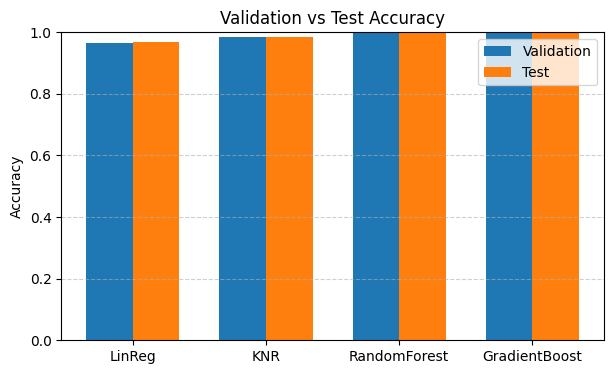

In [8]:
models = ["LinReg", "KNR", "RandomForest", "GradientBoost"]
val_accs = [r2_val_lin, r2_val_knr, r2_val_rf, r2_val_gbr]
test_accs = [r2_test_lin, r2_test_knr, r2_test_rf, r2_test_gbr]

x = np.arange(len(models))
width = 0.35
plt.figure(figsize=(7,4))
plt.bar(x - width/2, val_accs, width, label="Validation")
plt.bar(x + width/2, test_accs, width, label="Test")
plt.xticks(x, models)
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Validation vs Test Accuracy")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

# Model Evaluation

This is were we evaluate the two performance measure we recorded to decide the best model to use.
R2 (R-Squared) and MAE (Mean Average Error)

### R2 (R-Squared)
        This metric measures how good a model can determine the varience of the target variable that can be predicted from the feature variables the formuala - (SUM of errors) / (Sum of errors of mean model)
- **Interperatation** the closer the R2 score is to "1" the better the prediction
- **1.0** : 100% Perfected Prediction
- **.8-.99** : Very Good
- **.6-.79** : Okay
- **.4-.59** : Not Good
- **Anything Less** : Terrible

### The Best R2 Score is from:
- **Random Forest Regression** : 
- The R2 Validation score is :  0.9975256495634396
- The R2 Test score is :  0.9978179757866412

### MAE (Mean Absolute Error)
        This Metric tells us the average range of error in the prediction for calories, this basically tells us on average how far off the predicted calories are from the actual calories burned. if the MAE is 5.5 then that means that the model is off the actual caries burned by around 5.5 calories on average
 - **Interperetation**  the lower the MAE the better the model,

### The Best MAE  Score is from:
- **Random Forest Regression** :
- The MAE Validation score is :  1.9820046697798532
- The MAE Test score is :  1.8719112741827884

# Saving Best Model for Demo 

In [9]:
val_scores = {
    "Linear Regression": r2_val_lin,
    "K-Nearest Regressor": r2_val_knr,
    "Random Forest": r2_val_rf,
    "Gradient Boosting": r2_val_gbr
}
best_model_name = max(val_scores, key=val_scores.get)
print("Best model based on validation accuracy:", best_model_name)

best_model = {
    "Linear Regression": lin_reg,
    "K-Nearest Regressor": knr,
    "Random Forest": rf,
    "Gradient Boosting": gbr
}[best_model_name]

joblib.dump(best_model, "best_calorie_model.joblib")
print("Best model saved to best_calorie_model.joblib")

Best model based on validation accuracy: Random Forest
Best model saved to best_calorie_model.joblib


#### Code for references
all models code and demo application code came from brightspace, with only changes made to suit regression instead of classification 